In [9]:
import numpy as np, matplotlib.pyplot as plt, time
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.datasets import fashion_mnist
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
tf.random.set_seed(42); np.random.seed(42)

In [10]:
tf.random.set_seed(42); np.random.seed(42)
print("GPU:", tf.config.list_physical_devices("GPU"))

GPU: []


In [ ]:
######## 과제 1번
# ---------- 데이터 ----------
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()
x_train = x_train.astype("float32") / 255.; x_test = x_test.astype("float32") / 255.
x_train_c, x_test_c = x_train[..., None], x_test[..., None]
names = ['T-shirt','Trouser','Pullover','Dress','Coat','Sandal','Shirt','Sneaker','Bag','Ankle boot']


In [12]:
# ---------- 1) 일반 DNN (BN, skip 없음) ----------
def build_dnn():
    m = keras.Sequential([layers.Input((28, 28)), layers.Flatten()], name="DNN")
    for u in (512, 256, 128):
        m.add(layers.Dense(u, use_bias=False)); m.add(layers.BatchNormalization())
        m.add(layers.ReLU()); m.add(layers.Dropout(0.3))
    m.add(layers.Dense(10, activation="softmax"))
    m.compile("adam", "sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

In [13]:
# ---------- 2) ResDNN ----------
def dense_res_block(x, units, dropout=0.3):
    s = x
    x = layers.Dense(units, use_bias=False)(x)
    x = layers.ReLU()(layers.BatchNormalization()(x))
    x = layers.Dropout(dropout)(x)
    x = layers.Dense(units, use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    if s.shape[-1] != units:
        s = layers.BatchNormalization()(layers.Dense(units, use_bias=False)(s))
    return layers.ReLU()(layers.Add()([x, s]))

def build_res_dnn(units=(512, 256, 128)):
    i = layers.Input((28, 28))
    x = layers.Flatten()(i)
    for u in units:
        x = dense_res_block(x, u)
    o = layers.Dense(10, activation="softmax")(x)
    m = keras.Model(i, o, name="ResDNN")
    m.compile("adam", "sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

In [15]:
# ---------- 3) ResNet CNN ----------
def res_block(x, f):
    s = x
    x = layers.ReLU()(layers.BatchNormalization()(layers.Conv2D(f, 3, padding="same", use_bias=False)(x)))
    x = layers.BatchNormalization()(layers.Conv2D(f, 3, padding="same", use_bias=False)(x))
    if s.shape[-1] != f:
        s = layers.BatchNormalization()(layers.Conv2D(f, 1, use_bias=False)(s))
    return layers.ReLU()(layers.Add()([x, s]))

def build_cnn():
    i = layers.Input((28, 28, 1))
    x = layers.ReLU()(layers.BatchNormalization()(layers.Conv2D(32, 3, padding="same", use_bias=False)(i)))
    x = layers.MaxPooling2D()(res_block(x, 32))
    x = layers.MaxPooling2D()(res_block(x, 64))
    x = layers.Dropout(0.3)(layers.GlobalAveragePooling2D()(x))
    m = keras.Model(i, layers.Dense(10, activation="softmax")(x), name="ResNet_CNN")
    m.compile("adam", "sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

def cbs():
    return [keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True, monitor="val_accuracy"),
            keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=2)]


In [17]:
# ---------- 학습 및 평가 ----------
jobs = [(build_dnn(), x_train, x_test),
        (build_res_dnn(), x_train, x_test),
        (build_cnn(), x_train_c, x_test_c)]

results = {}
for model, xtr, xte in jobs:
    model.summary()
    t = time.time()
    h = model.fit(xtr, y_train, validation_split=0.1, epochs=100,
                  batch_size=256, callbacks=cbs(), verbose=2)
    sec = time.time() - t
    loss, acc = model.evaluate(xte, y_test, verbose=0)
    pred = model.predict(xte).argmax(1)
    print(f"[{model.name}] test acc={acc:.4f}, loss={loss:.4f}")
    print(classification_report(y_test, pred, target_names=names, digits=4))
    results[model.name] = dict(h=h, pred=pred, acc=acc, loss=loss, sec=sec, params=model.count_params())


Model: "DNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_2 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 512)            │       401,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_18          │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_14 (ReLU)                 │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 256)            │       131,072 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_19          │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_15 (ReLU)                 │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 128)            │        32,768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_20          │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_16 (ReLU)                 │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 570,122 (2.17 MB)

 Trainable params: 568,330 (2.17 MB)

 Non-trainable params: 1,792 (7.00 KB)

Epoch 1/100
211/211 - 2s - 11ms/step - accuracy: 0.7907 - loss: 0.6034 - val_accuracy: 0.8433 - val_loss: 0.4169 - learning_rate: 0.0010
Epoch 2/100
211/211 - 1s - 6ms/step - accuracy: 0.8516 - loss: 0.4170 - val_accuracy: 0.8525 - val_loss: 0.3894 - learning_rate: 0.0010
Epoch 3/100
211/211 - 1s - 6ms/step - accuracy: 0.8663 - loss: 0.3725 - val_accuracy: 0.8712 - val_loss: 0.3481 - learning_rate: 0.0010
Epoch 4/100
211/211 - 1s - 6ms/step - accuracy: 0.8750 - loss: 0.3459 - val_accuracy: 0.8713 - val_loss: 0.3545 - learning_rate: 0.0010
Epoch 5/100
211/211 - 1s - 6ms/step - accuracy: 0.8813 - loss: 0.3247 - val_accuracy: 0.8707 - val_loss: 0.3493 - learning_rate: 0.0010
Epoch 6/100
211/211 - 1s - 6ms/step - accuracy: 0.8908 - loss: 0.2967 - val_accuracy: 0.8797 - val_loss: 0.3229 - learning_rate: 5.0000e-04
Epoch 7/100
211/211 - 1s - 6ms/step - accuracy: 0.8981 - loss: 0.2802 - val_accuracy: 0.8867 - val_loss: 0.3137 - learning_rate: 5.0000e-04
Epoch 8/100
211/211 - 1s - 6ms/step - a

... (8 outputs left out)

 Total params: 77,866 (304.16 KB)

 Trainable params: 77,290 (301.91 KB)

 Non-trainable params: 576 (2.25 KB)

Epoch 1/100
211/211 - 64s - 302ms/step - accuracy: 0.6772 - loss: 0.9181 - val_accuracy: 0.1003 - val_loss: 4.9815 - learning_rate: 0.0010
Epoch 2/100
211/211 - 65s - 309ms/step - accuracy: 0.8134 - loss: 0.5303 - val_accuracy: 0.1038 - val_loss: 4.0534 - learning_rate: 0.0010
Epoch 3/100
211/211 - 60s - 286ms/step - accuracy: 0.8463 - loss: 0.4418 - val_accuracy: 0.7898 - val_loss: 0.5750 - learning_rate: 0.0010
Epoch 4/100
211/211 - 67s - 316ms/step - accuracy: 0.8616 - loss: 0.3908 - val_accuracy: 0.8638 - val_loss: 0.3701 - learning_rate: 0.0010
Epoch 5/100
211/211 - 61s - 291ms/step - accuracy: 0.8746 - loss: 0.3555 - val_accuracy: 0.8107 - val_loss: 0.5116 - learning_rate: 0.0010
Epoch 6/100
211/211 - 64s - 305ms/step - accuracy: 0.8831 - loss: 0.3297 - val_accuracy: 0.8185 - val_loss: 0.4869 - learning_rate: 0.0010
Epoch 7/100
211/211 - 62s - 294ms/step - accuracy: 0.8949 - loss: 0.2976 - val_accuracy: 0.8885 - val_loss: 0.3085 - learning_rate: 5.0000e-04
Epoch 8/100
211/211 - 6

Model           Params   TestAcc  TestLoss  Time(s)
DNN            570,122    0.8957    0.3081       31
ResDNN       1,486,602    0.9035    0.3308       65
ResNet_CNN      77,866    0.9191    0.2320     2635


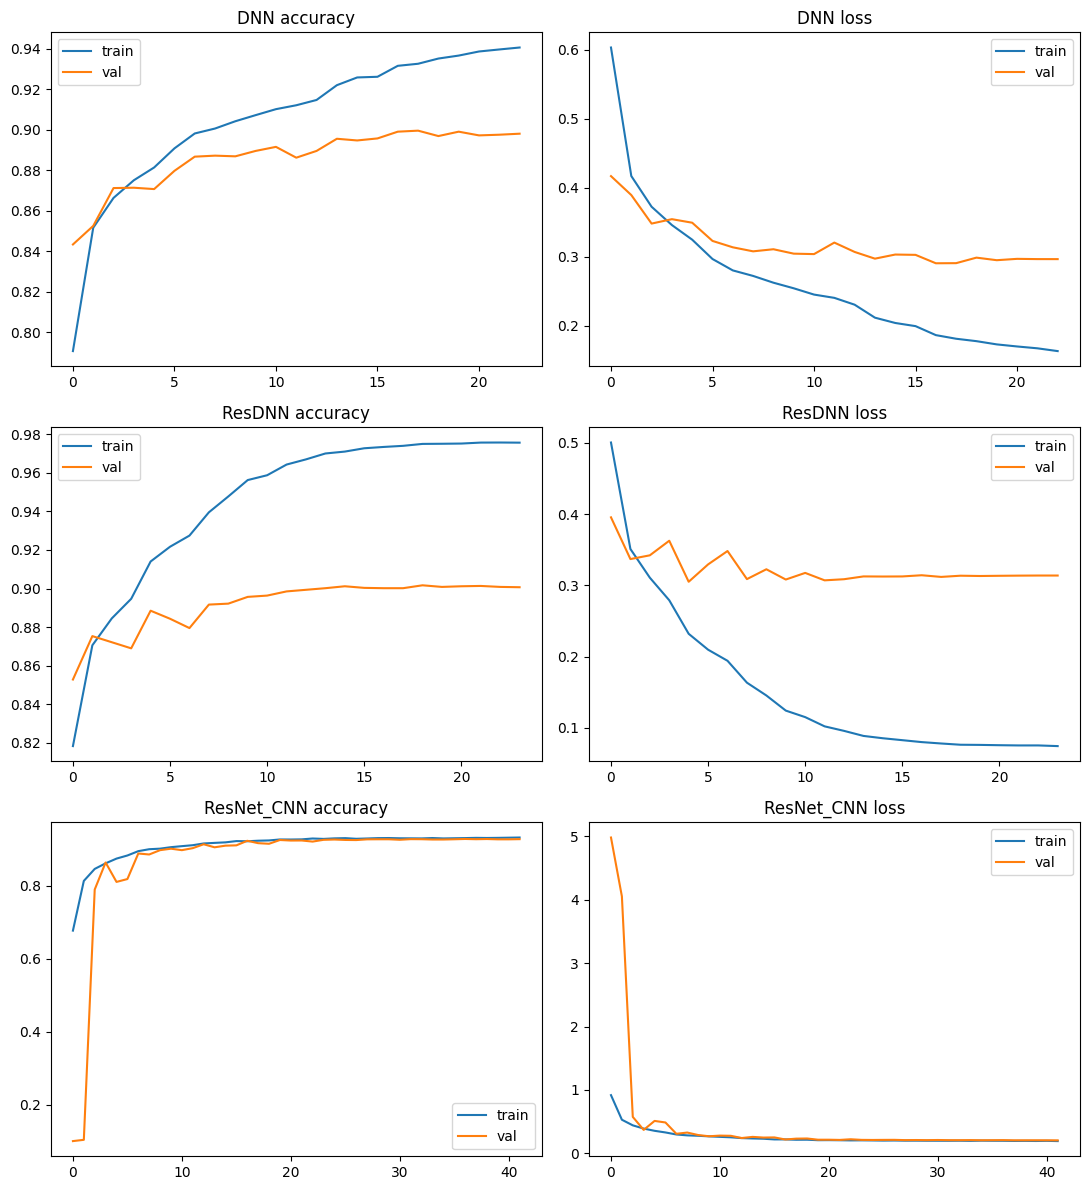

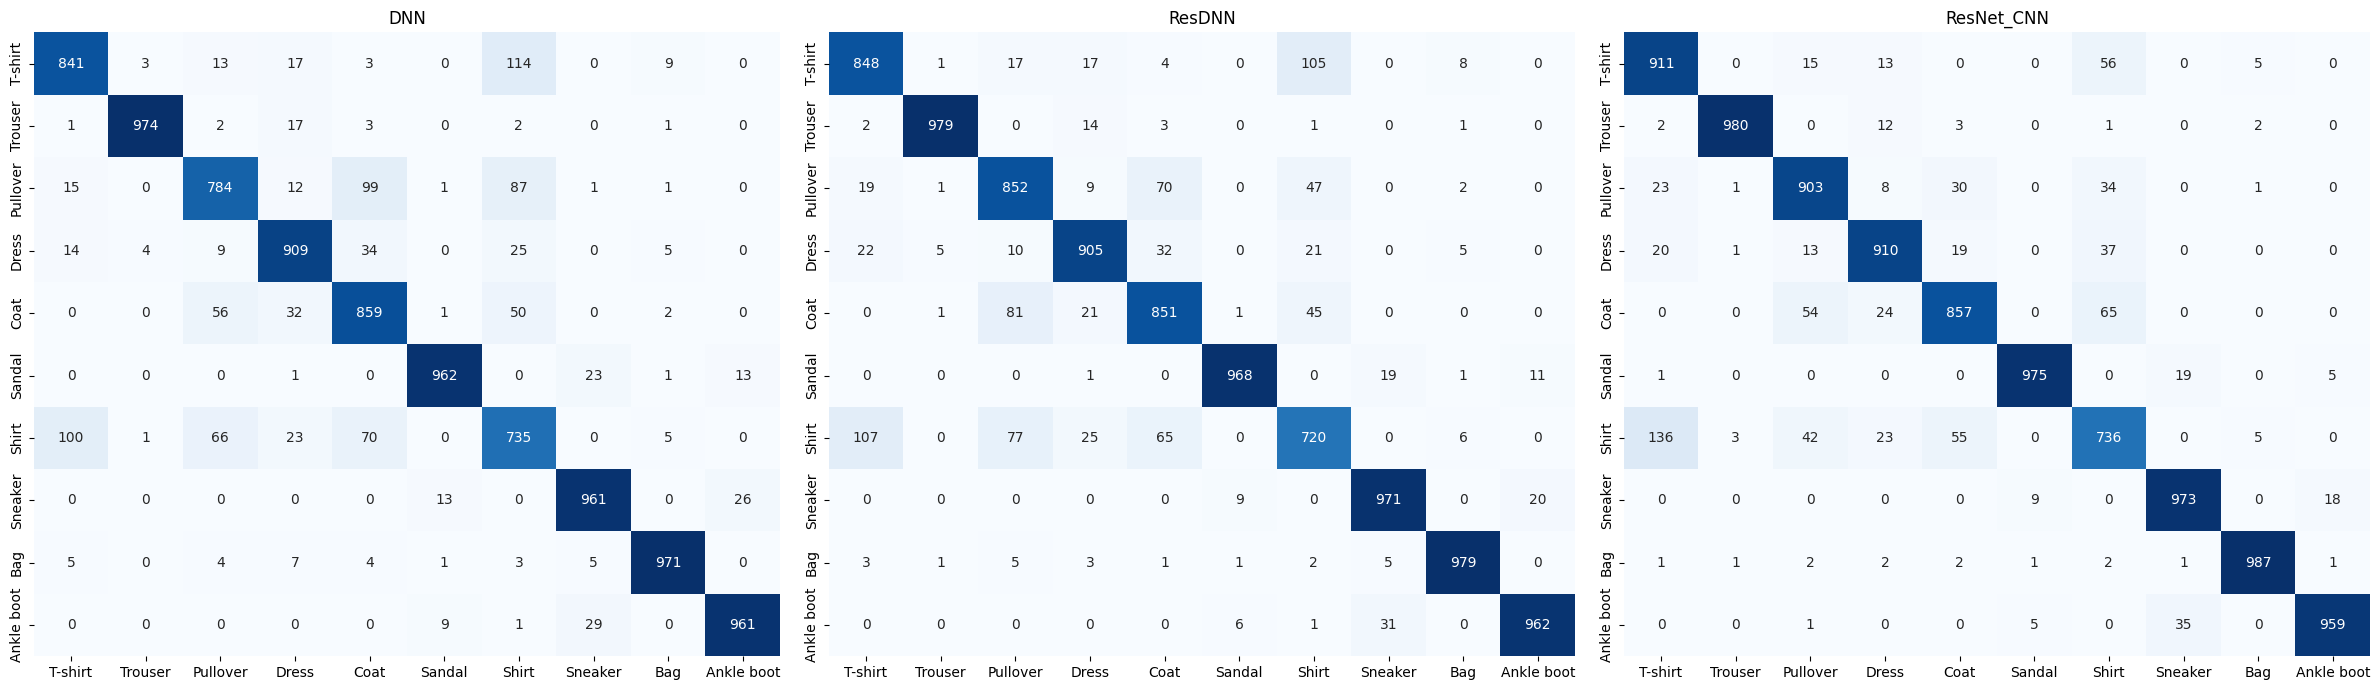

In [18]:
# ---------- 학습 곡선 ----------
fig, ax = plt.subplots(3, 2, figsize=(11, 12))
for r, (n, d) in enumerate(results.items()):
    for c, k in enumerate(["accuracy", "loss"]):
        ax[r, c].plot(d["h"].history[k], label="train")
        ax[r, c].plot(d["h"].history["val_" + k], label="val")
        ax[r, c].set_title(f"{n} {k}"); ax[r, c].legend()
plt.tight_layout(); plt.savefig("fmnist_curves.png", dpi=150)

# ---------- 혼동행렬 ----------
fig, ax = plt.subplots(1, 3, figsize=(24, 7))
for a, (n, d) in zip(ax, results.items()):
    sns.heatmap(confusion_matrix(y_test, d["pred"]), annot=True, fmt="d", cmap="Blues",
                xticklabels=names, yticklabels=names, ax=a, cbar=False)
    a.set_title(n)
plt.tight_layout(); plt.savefig("fmnist_cm.png", dpi=150)

# ---------- 비교표 ----------
print(f"{'Model':<12}{'Params':>10}{'TestAcc':>10}{'TestLoss':>10}{'Time(s)':>9}")
for n, d in results.items():
    print(f"{n:<12}{d['params']:>10,}{d['acc']:>10.4f}{d['loss']:>10.4f}{d['sec']:>9.0f}")

In [20]:
# ============================================================
# #1 - 4) 모델 파라미터 수(weights) 계산 과정
# ============================================================
#
# [1] 층별 파라미터 수 공식
#  - Dense (bias 있음)    : (n_in x n_out) + n_out
#  - Dense (bias 없음)    : n_in x n_out
#  - Conv2D (bias 없음)   : K x K x C_in x C_out
#  - BatchNormalization   : 4 x C  (gamma, beta = 학습 / 이동평균, 이동분산 = 비학습)
#  - Flatten, Pooling, ReLU, Dropout, Add : 0개
#  * Conv 필터는 위치마다 공유되므로 이미지 크기와 무관하고,
#    필터 크기와 채널 수로만 결정된다.
#
# ------------------------------------------------------------
# [2] DNN : 570,122개
#   Dense 784->512        : 784 x 512            = 401,408
#   Dense 512->256        : 512 x 256            = 131,072
#   Dense 256->128        : 256 x 128            =  32,768
#   BN (512, 256, 128)    : 4 x (512+256+128)    =   3,584
#   Dense 128->10 (출력)  : 128 x 10 + 10        =   1,290
#   --------------------------------------------------------
#   합계                                         = 570,122
#
# ------------------------------------------------------------
# [3] ResDNN : 1,486,602개
#   각 블록 = Dense(u) + Dense(u) + shortcut Dense(입력->u) + BN 3개
#   블록1 (784->512) : 784x512 + 512x512 + 784x512 = 1,064,960, BN 4x512x3 = 6,144
#   블록2 (512->256) : 512x256 + 256x256 + 512x256 =   327,680, BN 4x256x3 = 3,072
#   블록3 (256->128) : 256x128 + 128x128 + 256x128 =    81,920, BN 4x128x3 = 1,536
#   출력 Dense 128->10 : 128 x 10 + 10             =     1,290
#   --------------------------------------------------------
#   Dense 합 1,474,560 + BN 합 10,752 + 출력 1,290 = 1,486,602
#
# ------------------------------------------------------------
# [4] ResNet_CNN : 77,866개
#   stem Conv 1->32           : 3x3x1x32            =    288
#   블록1 Conv 32->32 (2개)   : 2 x (3x3x32x32)     = 18,432
#   블록2 Conv 32->64         : 3x3x32x64           = 18,432
#   블록2 Conv 64->64         : 3x3x64x64           = 36,864
#   블록2 shortcut Conv 1x1   : 1x1x32x64           =  2,048
#   BN 합계                   : stem 128 + 블록1 256 + 블록2 768 = 1,152
#   출력 Dense 64->10         : 64 x 10 + 10        =    650
#   --------------------------------------------------------
#   합계                                            = 77,866
#
# ------------------------------------------------------------
# [5] 결과 해석 (Fashion-MNIST 테스트 성능)
#   모델        Params      TestAcc   TestLoss
#   DNN         570,122     0.8957    0.3081
#   ResDNN    1,486,602     0.9035    0.3308
#   ResNet_CNN   77,866     0.9191    0.2320
#   - CNN은 파라미터가 DNN의 약 14%인데도 정확도가 가장 높고 손실이 가장 낮다.
#     => 합성곱의 지역 연결 + 파라미터 공유가 이미지에 효율적
#   - ResDNN은 DNN보다 파라미터가 2.6배 많지만 정확도는 소폭 상승하고, 오히려 테스트 손실은 더 높아졌다
# ============================================================



In [21]:
##### 과제 2번
import numpy as np, matplotlib.pyplot as plt, seaborn as sns, time
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.datasets import cifar10
from sklearn.metrics import confusion_matrix, classification_report

tf.random.set_seed(42); np.random.seed(42)

In [22]:
# ---------- 데이터 ----------
(x_train, y_train), (x_test, y_test) = cifar10.load_data()
y_train, y_test = y_train.ravel(), y_test.ravel()
x_train = x_train.astype("float32") / 255.; x_test = x_test.astype("float32") / 255.
mean, std = x_train.mean((0, 1, 2)), x_train.std((0, 1, 2))      # 채널별 표준화
x_train = (x_train - mean) / std; x_test = (x_test - mean) / std
names = ['airplane','automobile','bird','cat','deer','dog','frog','horse','ship','truck']

In [24]:

def augment():
    return keras.Sequential([layers.RandomFlip("horizontal"),
                             layers.RandomTranslation(0.1, 0.1)], name="augment")

In [26]:
# ---------- 1) ResDNN (BN + skip connection) ----------
def dense_res_block(x, units, dropout=0.3):
    s = x
    x = layers.Dense(units, use_bias=False)(x)
    x = layers.ReLU()(layers.BatchNormalization()(x))
    x = layers.Dropout(dropout)(x)
    x = layers.Dense(units, use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    if s.shape[-1] != units:
        s = layers.BatchNormalization()(layers.Dense(units, use_bias=False)(s))
    return layers.ReLU()(layers.Add()([x, s]))

def build_res_dnn(units=(1024, 512, 512, 256, 256)):
    i = layers.Input((32, 32, 3))
    x = augment()(i)
    x = layers.Flatten()(x)
    for u in units:
        x = dense_res_block(x, u)
    o = layers.Dense(10, activation="softmax")(x)
    m = keras.Model(i, o, name="ResDNN")
    m.compile("adam", "sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

In [27]:
# ---------- 2) ResNet CNN (BN + skip connection) ----------
def res_block(x, f):
    s = x
    x = layers.ReLU()(layers.BatchNormalization()(layers.Conv2D(f, 3, padding="same", use_bias=False)(x)))
    x = layers.BatchNormalization()(layers.Conv2D(f, 3, padding="same", use_bias=False)(x))
    if s.shape[-1] != f:
        s = layers.BatchNormalization()(layers.Conv2D(f, 1, use_bias=False)(s))
    return layers.ReLU()(layers.Add()([x, s]))

def build_cnn(filters=(32, 64, 128)):
    i = layers.Input((32, 32, 3))
    x = augment()(i)
    x = layers.ReLU()(layers.BatchNormalization()(layers.Conv2D(filters[0], 3, padding="same", use_bias=False)(x)))
    for f in filters:
        x = res_block(x, f); x = res_block(x, f)
        x = layers.MaxPooling2D()(x)                    # 32->16->8->4
    x = layers.Dropout(0.3)(layers.GlobalAveragePooling2D()(x))
    o = layers.Dense(10, activation="softmax")(x)
    m = keras.Model(i, o, name="ResNet_CNN")
    m.compile("adam", "sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

def cbs():
    return [keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True, monitor="val_accuracy"),
            keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=4)]

Model: "ResDNN"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_10      │ (None, 32, 32, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ augment             │ (None, 32, 32, 3) │          0 │ input_layer_10[0… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_5 (Flatten) │ (None, 3072)      │          0 │ augment[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_45 (Dense)    │ (None, 1024)      │  3,145,728 │ flatten_5[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 1024)      │      4,096 │ dense_45[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_51 (ReLU)     │ (None, 1024)      │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_20          │ (None, 1024)      │          0 │ re_lu_51[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_46 (Dense)    │ (None, 1024)      │  1,048,576 │ dropout_20[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_47 (Dense)    │ (None, 1024)      │  3,145,728 │ flatten_5[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 1024)      │      4,096 │ dense_46[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 1024)      │      4,096 │ dense_47[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_21 (Add)        │ (None, 1024)      │          0 │ batch_normalizat… │
│                     │                   │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_52 (ReLU)     │ (None, 1024)      │          0 │ add_21[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_48 (Dense)    │ (None, 512)       │    524,288 │ re_lu_52[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 512)       │      2,048 │ dense_48[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_53 (ReLU)     │ (None, 512)       │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_21          │ (None, 512)       │          0 │ re_lu_53[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_49 (Dense)    │ (None, 512)       │    262,144 │ dropout_21[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_50 (Dense)    │ (None, 512)       │    524,288 │ re_lu_52[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 512)       │      2,048 │ dense_49[0][0]    │
│ (BatchNormalizatio… │                   │            │                 

 Total params: 9,664,010 (36.87 MB)

 Trainable params: 9,650,186 (36.81 MB)

 Non-trainable params: 13,824 (54.00 KB)

Epoch 1/100
352/352 - 19s - 54ms/step - accuracy: 0.3253 - loss: 1.9285 - val_accuracy: 0.4196 - val_loss: 1.6499 - learning_rate: 0.0010
Epoch 2/100
352/352 - 16s - 46ms/step - accuracy: 0.4126 - loss: 1.6362 - val_accuracy: 0.4506 - val_loss: 1.5377 - learning_rate: 0.0010
Epoch 3/100
352/352 - 16s - 45ms/step - accuracy: 0.4475 - loss: 1.5400 - val_accuracy: 0.4894 - val_loss: 1.4246 - learning_rate: 0.0010
Epoch 4/100
352/352 - 16s - 46ms/step - accuracy: 0.4690 - loss: 1.4797 - val_accuracy: 0.5030 - val_loss: 1.3883 - learning_rate: 0.0010
Epoch 5/100
352/352 - 16s - 46ms/step - accuracy: 0.4846 - loss: 1.4356 - val_accuracy: 0.5256 - val_loss: 1.3300 - learning_rate: 0.0010
Epoch 6/100
352/352 - 16s - 47ms/step - accuracy: 0.5007 - loss: 1.3938 - val_accuracy: 0.5336 - val_loss: 1.3075 - learning_rate: 0.0010
Epoch 7/100
352/352 - 16s - 46ms/step - accuracy: 0.5099 - loss: 1.3673 - val_accuracy: 0.5424 - val_loss: 1.2877 - learning_rate: 0.0010
Epoch 8/100
352/352 - 16s - 45ms/s

... (2 outputs left out)

 Total params: 698,858 (2.67 MB)

 Trainable params: 696,618 (2.66 MB)

 Non-trainable params: 2,240 (8.75 KB)

Epoch 1/100
352/352 - 159s - 453ms/step - accuracy: 0.4226 - loss: 1.6273 - val_accuracy: 0.5086 - val_loss: 1.3130 - learning_rate: 0.0010
Epoch 2/100
352/352 - 155s - 440ms/step - accuracy: 0.6064 - loss: 1.1076 - val_accuracy: 0.6236 - val_loss: 1.1586 - learning_rate: 0.0010
Epoch 3/100
352/352 - 153s - 435ms/step - accuracy: 0.6900 - loss: 0.8826 - val_accuracy: 0.6022 - val_loss: 1.3240 - learning_rate: 0.0010
Epoch 4/100
352/352 - 154s - 437ms/step - accuracy: 0.7423 - loss: 0.7417 - val_accuracy: 0.7332 - val_loss: 0.8347 - learning_rate: 0.0010
Epoch 5/100
352/352 - 153s - 436ms/step - accuracy: 0.7775 - loss: 0.6474 - val_accuracy: 0.7562 - val_loss: 0.7192 - learning_rate: 0.0010
Epoch 6/100
352/352 - 160s - 455ms/step - accuracy: 0.7997 - loss: 0.5840 - val_accuracy: 0.7432 - val_loss: 0.8400 - learning_rate: 0.0010
Epoch 7/100
352/352 - 156s - 444ms/step - accuracy: 0.8195 - loss: 0.5308 - val_accuracy: 0.7686 - val_loss: 0.6997 - learning_rate: 0.0010
Epoch 8/100
352/352 

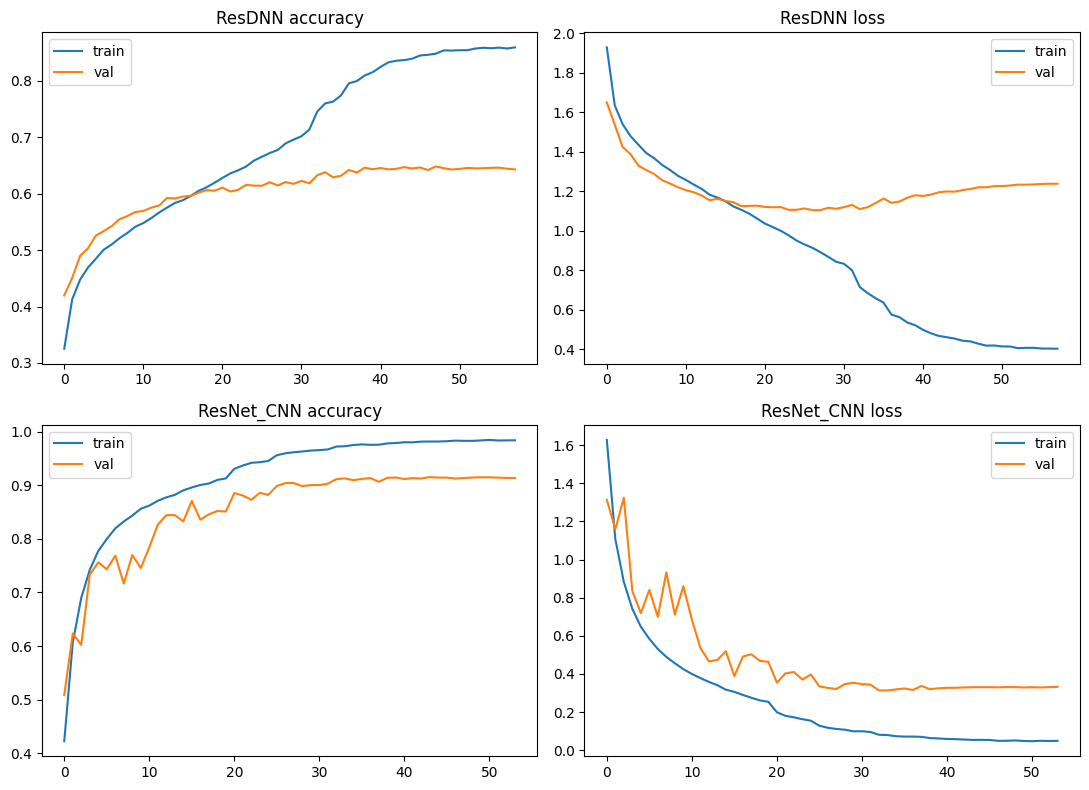

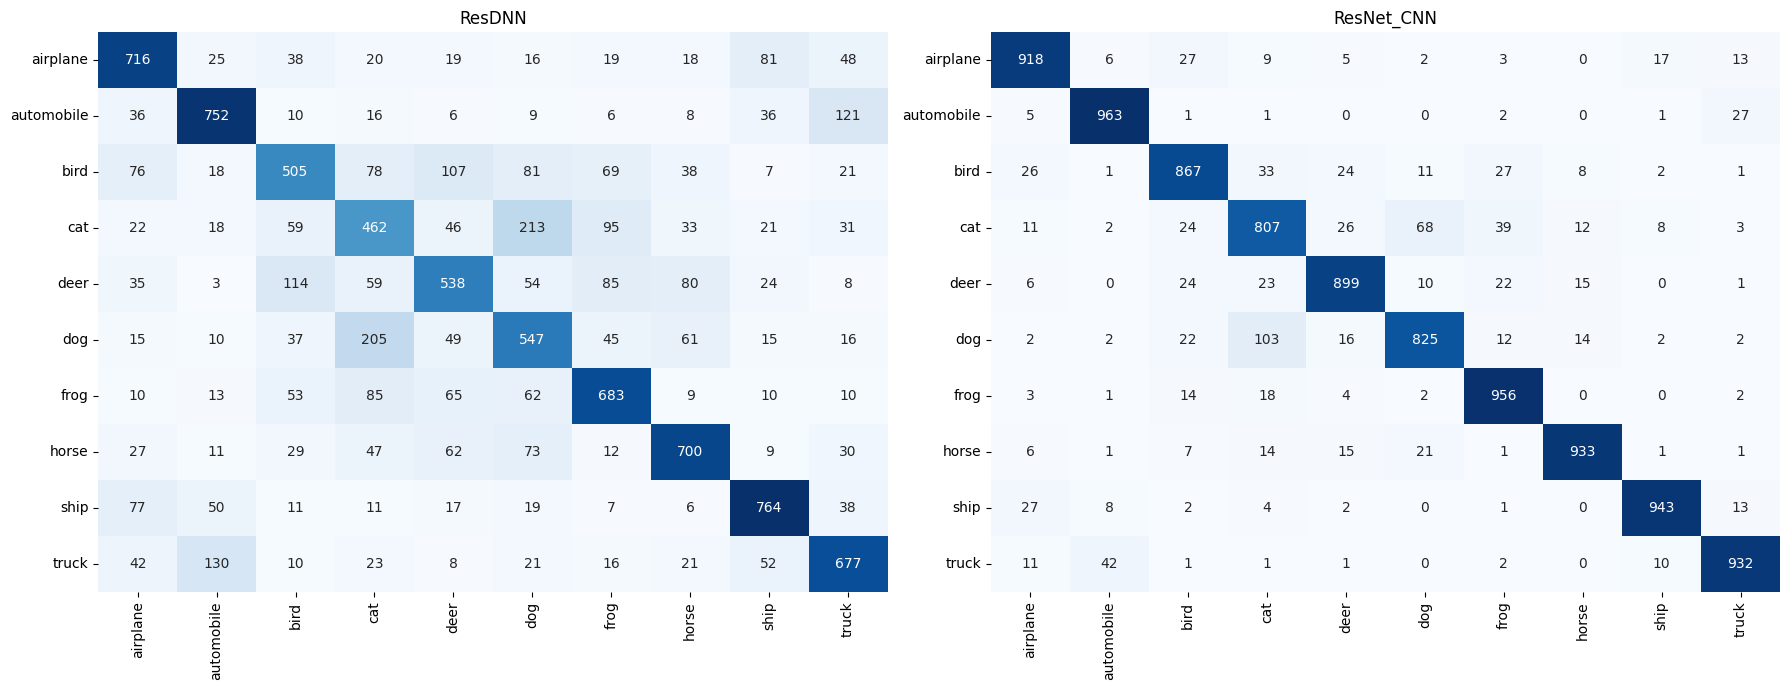

In [29]:
# ---------- 학습 및 평가 ----------
results = {}
for model in [build_res_dnn(), build_cnn()]:
    model.summary()
    t = time.time()
    h = model.fit(x_train, y_train, validation_split=0.1, epochs=100,
                  batch_size=128, callbacks=cbs(), verbose=2)
    sec = time.time() - t
    loss, acc = model.evaluate(x_test, y_test, verbose=0)
    pred = model.predict(x_test).argmax(1)
    print(f"[{model.name}] test acc={acc:.4f}, loss={loss:.4f}")
    print(classification_report(y_test, pred, target_names=names, digits=4))
    results[model.name] = dict(h=h, pred=pred, acc=acc, loss=loss, sec=sec, params=model.count_params())

# ---------- 학습 곡선 / 혼동행렬 ----------
fig, ax = plt.subplots(2, 2, figsize=(11, 8))
for r, (n, d) in enumerate(results.items()):
    for c, k in enumerate(["accuracy", "loss"]):
        ax[r, c].plot(d["h"].history[k], label="train")
        ax[r, c].plot(d["h"].history["val_" + k], label="val")
        ax[r, c].set_title(f"{n} {k}"); ax[r, c].legend()
plt.tight_layout(); plt.savefig("cifar_curves.png", dpi=150)

fig, ax = plt.subplots(1, 2, figsize=(18, 7))
for a, (n, d) in zip(ax, results.items()):
    sns.heatmap(confusion_matrix(y_test, d["pred"]), annot=True, fmt="d", cmap="Blues",
                xticklabels=names, yticklabels=names, ax=a, cbar=False); a.set_title(n)
plt.tight_layout(); plt.savefig("cifar_cm.png", dpi=150)

# ---------- 비교표 ----------
print(f"{'Model':<12}{'Params':>12}{'TestAcc':>10}{'TestLoss':>10}{'Epochs':>8}{'Time(s)':>9}")
for n, d in results.items():
    print(f"{n:<12}{d['params']:>12,}{d['acc']:>10.4f}{d['loss']:>10.4f}"
          f"{len(d['h'].history['loss']):>8}{d['sec']:>9.0f}")

In [30]:
# ============================================================
# #2 - 4) 모델 파라미터 수(weights) 계산 과정 (CIFAR-10)
# ============================================================
#
# [1] 층별 파라미터 수 공식
#  - Dense (bias 있음)    : (n_in x n_out) + n_out
#  - Dense (bias 없음)    : n_in x n_out
#  - Conv2D (bias 없음)   : K x K x C_in x C_out
#  - BatchNormalization   : 4 x C  (gamma, beta = 학습 / 이동평균, 이동분산 = 비학습)
#  - Flatten, Pooling, GAP, ReLU, Dropout, Add, 데이터 증강 층 : 0개
#  * Conv 필터는 위치마다 공유되므로 이미지 크기와 무관하고,
#    필터 크기와 채널 수로만 결정된다.
#  * BN 앞의 Dense/Conv는 use_bias=False (BN의 beta가 bias 역할)
#
# ------------------------------------------------------------
# [2] ResDNN : 9,664,010개
#   각 블록 = Dense(u) + Dense(u) + shortcut Dense(입력 != u일 때) + BN 2~3개
#   블록1 (3072->1024) : 3072x1024 + 1024x1024 + 3072x1024 = 7,340,032, BN 4x1024x3 = 12,288
#   블록2 (1024->512)  : 1024x512 + 512x512 + 1024x512     = 1,310,720, BN 4x512x3  =  6,144
#   블록3 (512->512)   : 512x512 + 512x512 (shortcut 없음) =   524,288, BN 4x512x2  =  4,096
#   블록4 (512->256)   : 512x256 + 256x256 + 512x256       =   327,680, BN 4x256x3  =  3,072
#   블록5 (256->256)   : 256x256 + 256x256 (shortcut 없음) =   131,072, BN 4x256x2  =  2,048
#   출력 Dense 256->10 : 256 x 10 + 10                     =     2,570
#   --------------------------------------------------------
#   Dense 합 9,633,792 + BN 합 27,648 + 출력 2,570 = 9,664,010
#   (비학습 13,824 / 학습 가능 9,650,186)
#   * 입력이 3072차원(32x32x3)이라 첫 블록에서만 약 7.3M개가 생긴다.
#
# ------------------------------------------------------------
# [3] ResNet_CNN : 698,858개
#   stem Conv 3->32                 : 3x3x3x32                                  =     864, BN 128
#   단계1 (32) ResBlock 2개         : 4 x (3x3x32x32)                           =  36,864, BN 4x128 = 512
#   단계2 (64) 블록1 32->64         : 3x3x32x64 + 3x3x64x64 + 1x1x32x64(sc)     =  57,344, BN 3x256 = 768
#              블록2 64->64         : 2 x (3x3x64x64)                           =  73,728, BN 2x256 = 512
#   단계3 (128) 블록1 64->128       : 3x3x64x128 + 3x3x128x128 + 1x1x64x128(sc) = 229,376, BN 3x512 = 1,536
#               블록2 128->128      : 2 x (3x3x128x128)                         = 294,912, BN 2x512 = 1,024
#   출력 Dense 128->10              : 128 x 10 + 10                             =   1,290
#   --------------------------------------------------------
#   Conv 합 693,088 + BN 합 4,480 + 출력 1,290 = 698,858
#
# ------------------------------------------------------------
# [4] 결과 해석 (CIFAR-10 테스트 성능)
#   모델            Params      TestAcc   TestLoss
#  ResDNN         9,664,010    0.6344    1.2735     
#  ResNet_CNN       698,858    0.9043    0.3643      
#   - CNN은 파라미터가 DNN의 약 7%인데도 정확도가 약 27% 높다.
#     => 합성곱의 지역 연결 + 파라미터 공유가 이미지에 효율적
#   - ResDNN은 파라미터가 약 14배 많지만 train 0.86 / val 0.64로 과적합이 심하다.
#     Dense는 공간 구조를 쓰지 못해 파라미터를 늘려도 일반화가 되지 않는다.
# ============================================================


NaN 개수:
 Series([], dtype: int64)
행 수: 8645
['season', 'mnth', 'day', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed']
변수 수 p = 12  train/test: 6916 1729
    Model     RMSE      MAE      R2  Time(s)
0     DNN  43.7468  29.2617  0.8968   9.9232
1  1D-CNN  69.6874  48.3712  0.7381   8.5985
2      RF  33.6983  20.7749  0.9388   1.7127


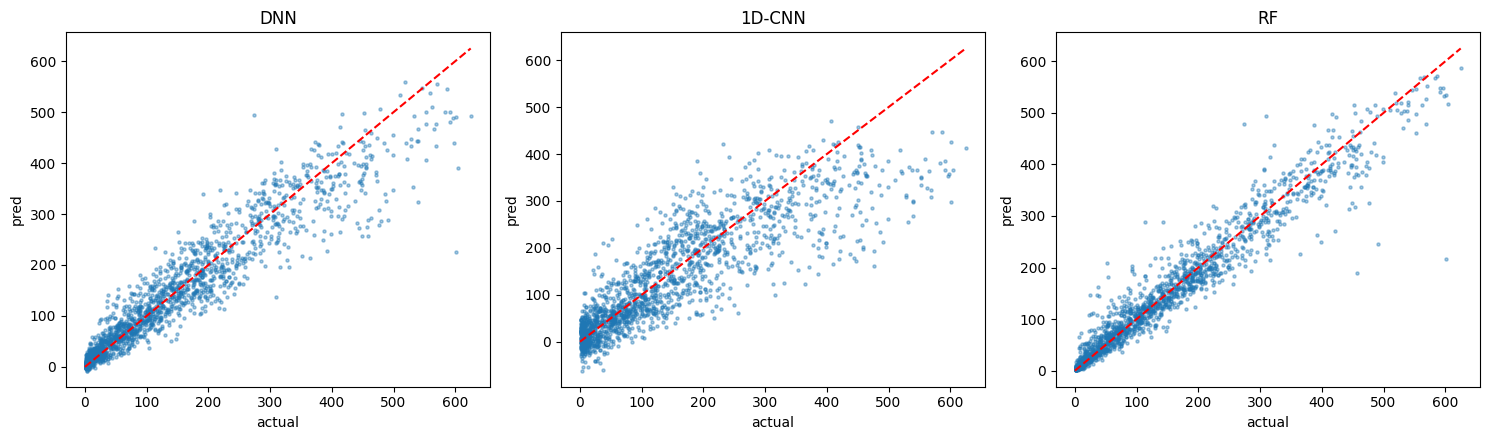

                DNN  1D-CNN       RF
season        8.818  21.986   13.201
mnth         15.064  32.765    0.369
day          18.109  22.234   16.170
hr          109.279  70.875  124.110
holiday       4.109   2.472    0.355
weekday       3.903  14.517    3.710
workingday   38.613  20.107   46.644
weathersit    5.109   1.989    5.341
temp         31.001  21.648   11.614
atemp        15.286  14.136   14.946
hum          10.670   8.961   14.322
windspeed     2.909   1.077    1.015


PermutationExplainer explainer: 201it [00:16,  5.02it/s]                         
PermutationExplainer explainer: 201it [00:17,  4.90it/s]                         


                RF     DNN  1D-CNN
season       8.753  10.181  12.452
mnth         0.675   7.697  16.615
day          9.693   9.314  14.453
hr          75.540  71.278  47.240
holiday      0.220   1.767   1.220
weekday      3.138   3.985  11.199
workingday  15.875  12.695  11.099
weathersit   5.195   7.978   5.226
temp        16.305  25.949  21.379
atemp       17.865   8.613  12.730
hum          8.438  10.657  15.735
windspeed    2.078   4.370   6.697


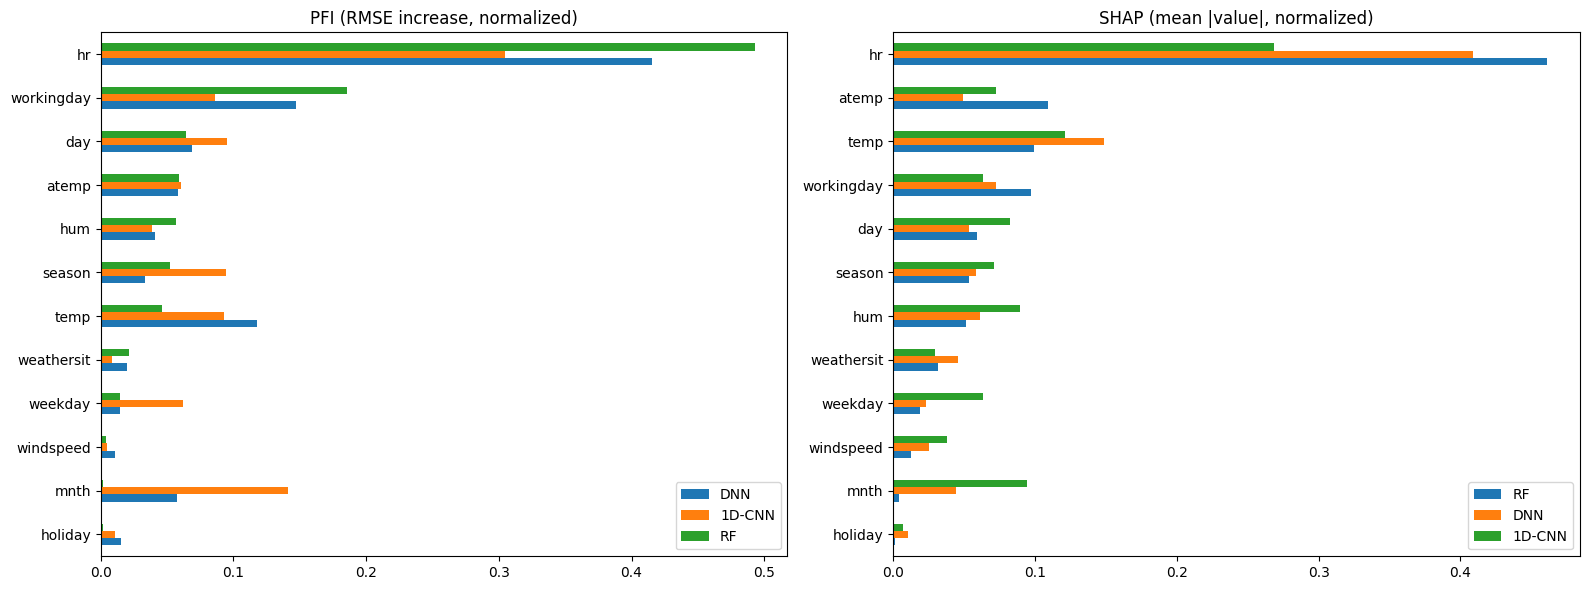

In [ ]:
##### 과제 3번
import numpy as np, pandas as pd, matplotlib.pyplot as plt, time
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
try:
    import shap; HAS_SHAP = True
except ImportError:
    HAS_SHAP = False; print("shap 없음 -> SHAP은 건너뜀")
tf.random.set_seed(42); np.random.seed(42)

# ==================== 데이터 ====================
PATH = "/Users/macbook/Desktop/3학년2학기/딥러닝/중간과제/bike.csv"
df = pd.read_csv(PATH, index_col=0)

def month_code(v):
    m = {"jan":1,"feb":2,"mar":3,"apr":4,"may":5,"jun":6,"jul":7,"aug":8,"sep":9,"oct":10,"nov":11,"dec":12}
    s = str(v).strip().lower()
    return m.get(s[:3], pd.to_numeric(s, errors="coerce"))

def weather_code(v):
    s = str(v).strip().lower()
    if "heavy" in s: return 4
    if "rain" in s or "snow" in s: return 3
    if "cloud" in s or "mist" in s: return 2
    if "clear" in s: return 1
    return pd.to_numeric(s, errors="coerce")        # 이미 숫자인 경우

df["mnth"] = df["mnth"].map(month_code)
df["weathersit"] = df["weathersit"].map(weather_code)
print("NaN 개수:\n", df.isna().sum()[df.isna().sum() > 0])
df = df.dropna().reset_index(drop=True)
print("행 수:", len(df))

TARGET = "bikers"
X = df.drop(columns=[TARGET, "casual", "registered"]).astype("float32")   # 누수 방지
y = df[TARGET].values.astype("float32")
feat = X.columns.tolist(); print(feat)

# ==================== 분할, 표준화 ====================
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)
sc = StandardScaler().fit(X_tr)
Xs_tr = sc.transform(X_tr).astype("float32")
ysc = StandardScaler().fit(y_tr.reshape(-1, 1))
y_tr_s = ysc.transform(y_tr.reshape(-1, 1)).ravel()
p = Xs_tr.shape[1]; print("변수 수 p =", p, " train/test:", len(X_tr), len(X_te))

# ==================== 모델 설정 ====================
def build_dnn():
    m = keras.Sequential([layers.Input((p,))])
    for u in (128, 64, 32):
        m.add(layers.Dense(u, use_bias=False)); m.add(layers.BatchNormalization())
        m.add(layers.ReLU()); m.add(layers.Dropout(0.1))
    m.add(layers.Dense(1)); m.compile("adam", "mse"); return m

def build_cnn1d():
    m = keras.Sequential([layers.Input((p, 1))])
    for f in (32, 64):
        m.add(layers.Conv1D(f, 3, padding="same", use_bias=False))
        m.add(layers.BatchNormalization()); m.add(layers.ReLU())
    m.add(layers.GlobalAveragePooling1D()); m.add(layers.Dense(32, activation="relu"))
    m.add(layers.Dense(1)); m.compile("adam", "mse"); return m

cb = lambda: [keras.callbacks.EarlyStopping(patience=15, restore_best_weights=True),
              keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=5)]

# ==================== 학습 ====================
dnn, cnn = build_dnn(), build_cnn1d()
t = time.time(); dnn.fit(Xs_tr, y_tr_s, validation_split=0.1, epochs=300, batch_size=128, callbacks=cb(), verbose=0); t_dnn = time.time() - t
t = time.time(); cnn.fit(Xs_tr[..., None], y_tr_s, validation_split=0.1, epochs=300, batch_size=128, callbacks=cb(), verbose=0); t_cnn = time.time() - t
t = time.time(); rf = RandomForestRegressor(500, n_jobs=-1, random_state=42).fit(X_tr, y_tr); t_rf = time.time() - t

def to_df(A): return A if isinstance(A, pd.DataFrame) else pd.DataFrame(A, columns=feat)
def pred_dnn(A): return ysc.inverse_transform(dnn.predict(sc.transform(to_df(A)).astype("float32"), verbose=0)).ravel()
def pred_cnn(A): return ysc.inverse_transform(cnn.predict(sc.transform(to_df(A)).astype("float32")[..., None], verbose=0)).ravel()
def pred_rf(A):  return rf.predict(to_df(A))
models = {"DNN": pred_dnn, "1D-CNN": pred_cnn, "RF": pred_rf}
times = {"DNN": t_dnn, "1D-CNN": t_cnn, "RF": t_rf}

# ==================== 3-1) 예측 성능 비교 ====================
rows = []
for n, f in models.items():
    pr = f(X_te); assert not np.isnan(pr).any(), f"{n} 예측에 NaN"
    rows.append([n, np.sqrt(mean_squared_error(y_te, pr)), mean_absolute_error(y_te, pr), r2_score(y_te, pr), times[n]])
perf = pd.DataFrame(rows, columns=["Model", "RMSE", "MAE", "R2", "Time(s)"]).round(4)
print(perf)

fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
for a, (n, f) in zip(ax, models.items()):
    a.scatter(y_te, f(X_te), s=5, alpha=.4); a.plot([0, y_te.max()], [0, y_te.max()], "r--")
    a.set_title(n); a.set_xlabel("actual"); a.set_ylabel("pred")
plt.tight_layout(); plt.savefig("bike_pred.png", dpi=150); plt.show()

# ==================== 3-2) PFI ====================
def pfi(f, Xd, yv, n_rep=5, seed=0):
    rng = np.random.default_rng(seed); base = np.sqrt(mean_squared_error(yv, f(Xd))); out = []
    for c in Xd.columns:
        d = []
        for _ in range(n_rep):
            Xp = Xd.copy(); Xp[c] = rng.permutation(Xp[c].values)
            d.append(np.sqrt(mean_squared_error(yv, f(Xp))) - base)
        out.append(np.mean(d))
    return pd.Series(out, index=Xd.columns)
pfi_df = pd.DataFrame({n: pfi(f, X_te, y_te) for n, f in models.items()})
print(pfi_df.round(3))

# ==================== 3-2) SHAP ====================
shap_df = None
if HAS_SHAP:
    bg = X_tr.sample(100, random_state=0); xs = X_te.sample(200, random_state=0)
    d = {"RF": pd.Series(np.abs(shap.TreeExplainer(rf).shap_values(xs)).mean(0), index=feat)}
    for n in ["DNN", "1D-CNN"]:
        ex = shap.Explainer(lambda A, f=models[n]: f(to_df(A)), bg.values, algorithm="permutation")
        d[n] = pd.Series(np.abs(ex(xs.values, max_evals=2 * p + 1).values).mean(0), index=feat)
    shap_df = pd.DataFrame(d); print(shap_df.round(3))

# ==================== 중요도 그림 ====================
norm = lambda D: D.clip(lower=0) / D.clip(lower=0).sum()
panels = [("PFI (RMSE increase, normalized)", pfi_df)] + ([("SHAP (mean |value|, normalized)", shap_df)] if shap_df is not None else [])
fig, ax = plt.subplots(1, len(panels), figsize=(8 * len(panels), 6), squeeze=False)
for a, (t_, D) in zip(ax[0], panels):
    norm(D).sort_values("RF").plot.barh(ax=a, title=t_)
plt.tight_layout(); plt.savefig("bike_importance.png", dpi=150); plt.show()



In [ ]:
# ============================================================
# #3-1) DNN, 1D-CNN, RF 예측 성능 비교 (bikeshare, 테스트셋)
# ============================================================
#   모델      RMSE     MAE      R2
#   DNN      43.75    29.26    0.8968
#   1D-CNN   69.69    48.37    0.7381
#   RF       33.70    20.77    0.9388
#
#  - RF가 모든 지표에서 가장 좋다 (R2 0.939). RMSE는 DNN보다 약 23% 낮다.
#  - DNN은 R2 0.897로 그다음이고, 1D-CNN은 R2 0.738로 가장 낮다.
#  - 예측-실제 산점도에서도 RF가 대각선에 가장 가깝다. DNN과 1D-CNN은
#    대여 수가 많은 구간에서 과소예측하고, 1D-CNN은 퍼짐이 가장 크다.
# ============================================================


# ============================================================
# #3-2) PFI, SHAP 변수 중요도 비교 (DNN, 1D-CNN, RF)
# ============================================================
# [PFI : 변수를 섞었을 때 늘어나는 RMSE, 상위 변수]
#   DNN    : hr 109.3 > workingday 38.6 > temp 31.0 > day 18.1
#   1D-CNN : hr 70.9  > mnth 32.8 > day 22.2 > season 22.0 > temp 21.6
#   RF     : hr 124.1 > workingday 46.6 > day 16.2 > atemp 14.9 > hum 14.3
# [SHAP : 평균 |SHAP|, 상위 변수]
#   DNN    : hr 71.3 > temp 25.9 > workingday 12.7 > hum 10.7
#   1D-CNN : hr 47.2 > temp 21.4 > mnth 16.6 > hum 15.7 > day 14.5
#   RF     : hr 75.5 > atemp 17.9 > temp 16.3 > workingday 15.9
#
# [공통점]
#  - 세 모델, 두 방법 모두에서 hr(시간대)이 압도적 1위이다.
#    출퇴근 시간대에 대여 수가 급증하는 패턴이 가장 큰 예측 요인이다.
#  - 그다음은 workingday, temp/atemp, hum이고,
#    holiday, windspeed, weathersit은 모든 모델에서 중요도가 낮다.
#
# [모델 간 차이]
#  - DNN과 RF는 중요도 순위가 비슷하다(hr > workingday, temp 계열)
#  - 1D-CNN은 hr 비중이 가장 낮고(PFI 70.9, SHAP 47.2) mnth, season, weekday 등
#    다른 변수에 중요도가 퍼져 있다. 특히 mnth는 1D-CNN에서 크지만(PFI 32.8)
#    RF에서는 거의 0(0.4)이다. 인접 변수를 묶는 합성곱 구조가 의미 없는
#    조합을 학습한 결과로 보이며, 성능이 낮은 것과 일치한다.
#  - temp와 atemp는 서로 거의 같은 정보라 중요도가 둘로 나뉘어 나타난다
#    (RF: SHAP atemp 17.9, temp 16.3 / PFI temp 11.6, atemp 14.9).
#
# [PFI와 SHAP의 차이]
#  - workingday는 PFI에서 크고(DNN 38.6, RF 46.6) SHAP에서는 상대적으로 작다
#    (12.7, 15.9). PFI는 변수를 섞었을 때 성능이 얼마나 나빠지는지,
#    SHAP은 예측값에 평균적으로 얼마나 기여하는지를 보기 때문이다.
#    workingday는 hr과의 상호작용(출퇴근 패턴)이 커서 섞으면 성능 손실이 크다.
#  - day(월의 일자)는 의미 없는 변수인데도 모든 모델에서 중간 수준(PFI 16~22)이다.
#    학습 데이터의 노이즈나 우연한 패턴을 학습했을 가능성이 있다.
#  - SHAP, PFI는 모두 상관된 변수(temp, atemp)가 있으면 중요도가 분산되므로
#    해석에 주의해야 한다.
# ============================================================


